In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.11/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.11/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
# Environment for testing
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState

import numpy as np
import itertools as it
import matplotlib.pyplot as plt

In [ ]:
from qBaseDistR import qbaseDist

In [ ]:
# Define environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],  # poor env
               [0.9, 0.1]])

env = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)
env

DistTwoArmedBanditOneState_1_-1_0.3_0.1

In [ ]:
qb = qbaseDist(env,
               nr_reward_bins=29,
               discretization_sigma=0.1,
               learning_rates=0.1,
               discount_factors=0.9,
               Rmin=-2,
               Rmax=2)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
def plot_Risjasr(i, s, s_, Rr=qb.Rr, gpoints=qb.gridpoints, wdth=qb.gridwidth):
    fig, axes = plt.subplots(1, 2, figsize=(8,3))
    for a, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Rr[i,s,a,s_,:], width=0.9*wdth, color='k')
        ax.set_xlabel("Risjasr")
        ax.set_title("Reward for action "+str(a)+" in state "+str(s_))
        ax.set_ylim([0, np.max(Rr[:,:,a,:])+0.01])

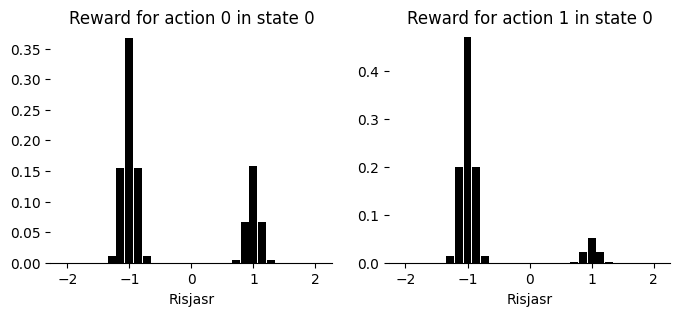

In [ ]:
plot_Risjasr(i=0, s=0, s_=0, Rr=qb.Rr, gpoints=qb.gridpoints, wdth=qb.gridwidth)

In [ ]:
np.sum(qb.Rr[0, 0, 0, 0, :14])

0.6999999860017644